# Mechanical vs neutral: is the gap the same as emotional vs neutral?

**Question:** `fulltrace_analysis_matched.ipynb` found that emotional prompts (**E**) produce about 3.5–4% more CPU throttling than neutral prompts (**N**). Do mechanical prompts (**M**) show the same gap? If they do, the E−N difference is probably about the *type of workload*, not the *emotional content*.

**Data:** mechanical runs exist only in `batch_004_enm`: **5 nodes on one date**, with one E, one N and one M run each. As in the main notebook, we only compare runs from the same node on the same date.

**Measures** (same as the main notebook; PTE = processor throttle events):
- **PTE mean rate** — throttle events per second.
- **PTE / cycles** — throttle events per CPU cycle.

**Three comparisons per node**, each as a % difference:
- **M vs N** — does mechanical differ from neutral?
- **E vs N** — the main notebook's comparison, on these same 5 nodes.
- **E vs M** — the direct test. Since log(E/N) − log(M/N) = log(E/M), "E vs M = 0" means "the E−N gap equals the M−N gap".

**Why the method is simpler than in the main notebook:** with a single date, a date term can't be separated from the overall effect, and each node appears only once. The main notebook's model therefore reduces to *average + noise*, which is a one-sample t-test on the 5 per-node differences. We also report an exact sign-flip test that makes no normality assumption.

Positive numbers mean the first condition is higher.

In [1]:
from pathlib import Path
import sys, hashlib, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data/features/recomputed/fulltrace").is_dir())
sys.path.insert(0, str(ROOT / "analysis/lib"))
import fulltrace_node_day
from fulltrace_matched import display_effect, SPECS as ALL_SPECS

# The shared loader keeps only E/N by default; also admit mechanical runs.
fulltrace_node_day.CONDITIONS = ("emotional", "neutral", "mechanical")

SELECTED_FEATURES = {"core_power.throttle__mean_rate",
                     "core_power.throttle__per_cycle"}
RENAME = {"core_power.throttle__mean_rate": "PTE mean rate"}
SPECS = [(feature, RENAME.get(feature, label), scale, unit)
         for feature, label, scale, unit in ALL_SPECS if feature in SELECTED_FEATURES]

TIMEZONE = "America/Chicago"
COMPARISONS = [("mechanical", "neutral", "M vs N"),
               ("emotional", "neutral", "E vs N"),
               ("emotional", "mechanical", "E vs M")]
EN_RESULTS = ROOT / "results/fulltrace_matched_EN_2026-10-24_two_features/overall_effects.csv"
OUT = ROOT / "results/fulltrace_matched_MN_2026-10-24_two_features"
OUT.mkdir(parents=True, exist_ok=True)
COLORS = {"emotional": "#C44E52", "neutral": "#4477AA", "mechanical": "#55A868"}
FEATURES = [s[0] for s in SPECS]
LABELS = {s[0]: s[1] for s in SPECS}
pd.set_option("display.max_rows", 100)

def save_figure(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Find nodes/dates with all three conditions

Same inclusion rules as the main notebook: successful 70B runs with recomputed feature files, dated by start time in Chicago time. We keep only node/date pairs that have **E, N and M** runs.

The run-order table matters for interpretation: it shows **when** each condition ran.

In [2]:
all_traces, _, sources, excluded = fulltrace_node_day.load_recordings(ROOT, TIMEZONE)
present = all_traces.groupby(["node", "day"]).condition.agg(set)
keys = present[present.apply(lambda s: {"emotional", "neutral", "mechanical"} <= s)].index
traces = all_traces.set_index(["node", "day"]).loc[keys].reset_index()
traces = traces.loc[:, [c for c in traces if "__" not in c or c in FEATURES]]
for column in ["n_prompts", "n_predict", "inter_prompt_pause_s", "model_size", "batch"]:
    if traces[column].nunique() != 1:
        raise ValueError(f"Mixed collection settings: {column}")
sources = sources.loc[sources.path.isin(set(traces.feature_file) | set(traces.metadata_file))]

print(f"{len(traces)} runs, {len(keys)} node/date pairs, batch {traces.batch.iloc[0]}")
display(pd.crosstab([traces.day, traces.node], traces.condition))
order = traces.sort_values("started_local")[["node", "condition", "run_label", "started_local", "dur_s"]]
order["start_time"] = order.pop("started_local").str[11:19]
display(order.reset_index(drop=True))
for name, table in [("input_recordings", traces), ("input_checksums", sources)]:
    table.to_csv(OUT / f"{name}.csv", index=False)

15 runs, 5 node/date pairs, batch batch_004_enm


condition        emotional  mechanical  neutral
day        node                                
2026-10-12 184           1           1        1
           230           1           1        1
           231           1           1        1
           232           1           1        1
           239           1           1        1

,node,condition,run_label,dur_s,start_time
0,184,neutral,184_N_1,1141.827843,11:22:12
1,232,neutral,232_N_1,1135.572757,11:22:33
2,231,mechanical,231_M_1,1116.020877,11:24:26
3,230,mechanical,230_M_1,1103.685686,11:24:42
4,239,mechanical,239_M_1,1110.349559,11:24:49
5,184,mechanical,184_M_1,1103.924737,11:59:57
6,232,mechanical,232_M_1,1105.556380,12:00:10
7,231,neutral,231_N_1,1122.530952,12:00:28
8,230,neutral,230_N_1,1124.914719,12:00:46
9,239,neutral,239_N_1,1146.677348,12:00:53


## 2. One difference per node

For each node, average the runs of each condition (here there is one run each), then compare two conditions as a ratio:

> difference = A / B − 1, shown as a percentage (the tests use log(A / B))

**Left plot:** each line is one node, showing how far M and E each sit above (or below) that node's own N run. If the M and E points are at the same height, the two gaps are the same.
**Right plot:** the E vs M difference per node. Red = E higher, green = M higher.

comparison          E vs M  E vs N  M vs N
label         node                        
PTE / cycles  184    -2.05    4.34    6.52
              230     2.94    3.95    0.98
              231     3.32    0.22   -3.00
              232    -0.04    2.14    2.19
              239     0.17    4.67    4.50
PTE mean rate 184    -1.45    3.96    5.49
              230     2.48    3.86    1.35
              231     2.48    0.44   -1.99
              232     0.02    2.23    2.21
              239    -0.04    4.15    4.20

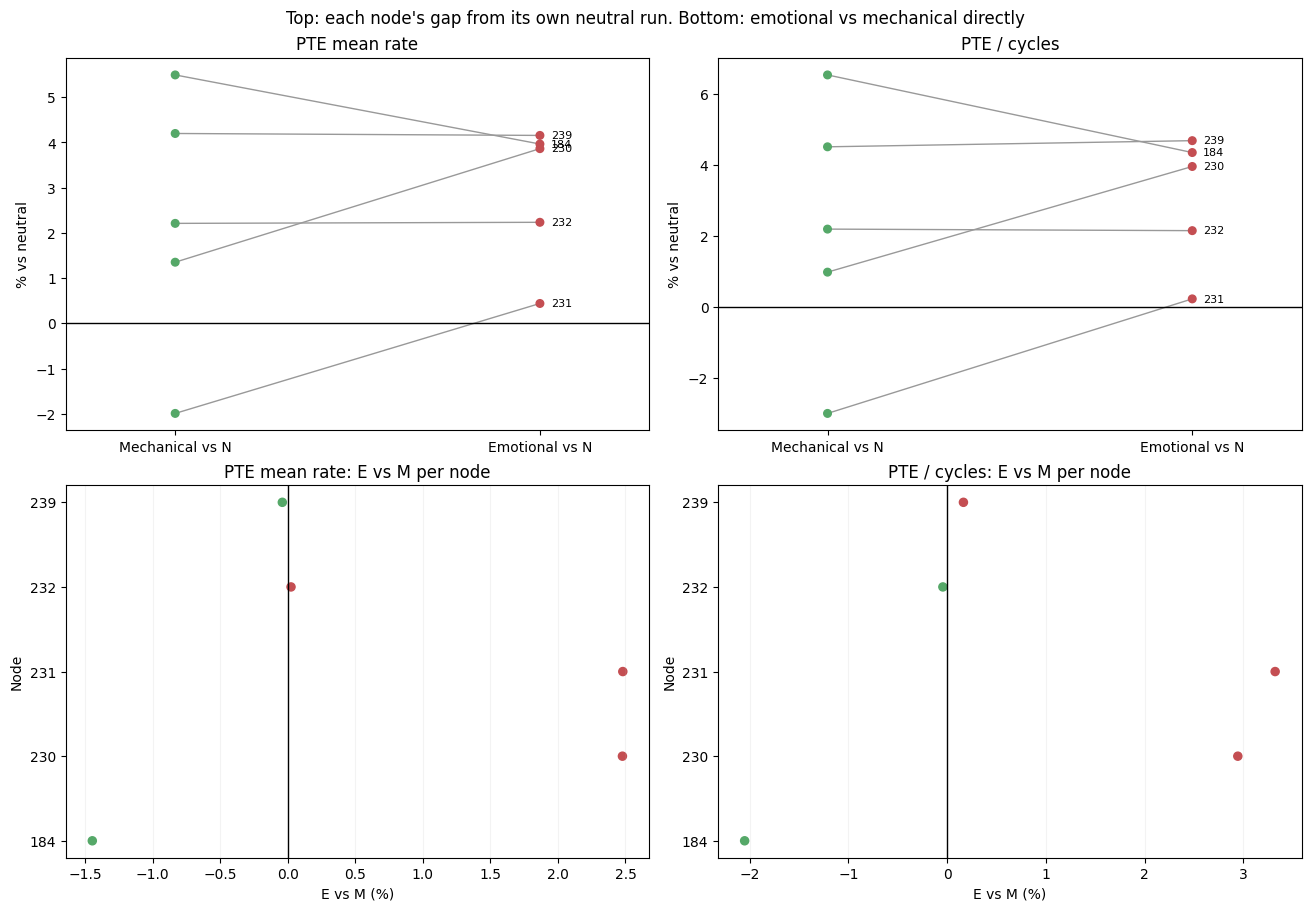

In [3]:
means = traces.groupby(["node", "day", "condition"])[FEATURES].mean()
rows = []
for (node, day), cell in means.groupby(level=["node", "day"]):
    cell = cell.droplevel(["node", "day"])
    for a, b, name in COMPARISONS:
        for feature, label, scale, unit in SPECS:
            contrast = np.log(cell.loc[a, feature] / cell.loc[b, feature])
            rows.append(dict(node=node, day=day, comparison=name, feature=feature, label=label,
                             unit=unit, contrast=contrast, effect=float(display_effect(contrast, scale))))
contrasts = pd.DataFrame(rows)
contrasts.to_csv(OUT / "matched_contrasts.csv", index=False)
display(contrasts.pivot_table(index=["label", "node"], columns="comparison", values="effect").round(2))

fig, axes = plt.subplots(2, len(SPECS), figsize=(13, 9), layout="constrained")
for (top, bottom), (feature, label, scale, unit) in zip(axes.T, SPECS):
    sub = contrasts.loc[contrasts.feature == feature].pivot(index="node", columns="comparison", values="effect")
    for node, row in sub.iterrows():
        top.plot([0, 1], [row["M vs N"], row["E vs N"]], color="#999999", linewidth=1)
        top.scatter([0, 1], [row["M vs N"], row["E vs N"]],
                    color=[COLORS["mechanical"], COLORS["emotional"]], s=30, zorder=3)
        top.annotate(node, (1.03, row["E vs N"]), fontsize=8, va="center")
    top.axhline(0, color="black", linewidth=1)
    top.set(xticks=[0, 1], xticklabels=["Mechanical vs N", "Emotional vs N"], xlim=(-.3, 1.3),
            title=label, ylabel=unit)
    values = sub["E vs M"].sort_index()
    bottom.scatter(values, range(len(values)), s=34,
                   color=[COLORS["emotional"] if v > 0 else COLORS["mechanical"] for v in values])
    bottom.axvline(0, color="black", linewidth=1)
    bottom.set(yticks=range(len(values)), yticklabels=values.index, ylabel="Node",
               xlabel="E vs M (%)", title=f"{label}: E vs M per node")
    bottom.grid(axis="x", alpha=.15)
fig.suptitle("Top: each node's gap from its own neutral run. Bottom: emotional vs mechanical directly")
save_figure(fig, "per_node_differences")

## 3. Average difference and tests

For each comparison and measure we compute, over the 5 nodes:

- **Average difference**, with a **95% CI** from the t-distribution (4 degrees of freedom).
- **t-test p** — is the average difference zero? Bonferroni-corrected for the two measures (p × 2).
- **Sign-flip p** — an exact test: flip the sign of each node's difference in all 2⁵ = 32 ways and see how often the average is at least as large. With only 5 nodes, it **can't go below 0.0625**, so it can never reach 0.05 by itself; it serves as a robustness check.

**Reference:** the E−N estimate from the main notebook (22 pairs, 7 dates) is shown alongside. If the M−N range covers it, mechanical prompts are compatible with the same gap as emotional ones.

**Reading "not significant":** with 5 nodes, a real difference can easily go undetected. A non-significant E vs M test does **not** show that the gaps are equal. The CI shows which differences are still plausible.

In [4]:
def sign_flip_p(values):
    signs = np.array(list(itertools.product([1, -1], repeat=len(values))))
    null = np.abs((signs * values).mean(axis=1))
    return float((null >= abs(values.mean()) - 1e-12).mean())

summary = []
for (name, feature), sub in contrasts.groupby(["comparison", "feature"], sort=False):
    values = sub.contrast.to_numpy(float)
    n, mean, se = len(values), values.mean(), values.std(ddof=1) / np.sqrt(len(values))
    half = stats.t.ppf(.975, n - 1) * se
    scale = next(s[2] for s in SPECS if s[0] == feature)
    summary.append(dict(comparison=name, feature=feature, label=LABELS[feature], n_nodes=n,
                        estimate=float(display_effect(mean, scale)),
                        ci_low=float(display_effect(mean - half, scale)),
                        ci_high=float(display_effect(mean + half, scale)),
                        p_t=stats.ttest_1samp(values, 0).pvalue, p_sign_flip=sign_flip_p(values),
                        n_positive=int((values > 0).sum())))
summary = pd.DataFrame(summary)
summary["p_t_bonferroni"] = (2 * summary.p_t).clip(upper=1)
summary.to_csv(OUT / "overall_effects.csv", index=False)

reference = pd.read_csv(EN_RESULTS).set_index("feature")
report = pd.DataFrame({"Comparison": summary.comparison, "Feature": summary.label,
    "Average (%)": summary.estimate, "95% CI lower": summary.ci_low, "95% CI upper": summary.ci_high,
    "Bonferroni t-test p": summary.p_t_bonferroni, "Sign-flip p": summary.p_sign_flip,
    "First higher": [f"{p}/{n}" for p, n in zip(summary.n_positive, summary.n_nodes)]})
display(report.round(4))
report.to_csv(OUT / "readable_summary.csv", index=False)
display(Markdown("**Main notebook E vs N (22 pairs):** " + "; ".join(
    f"{LABELS[f]} {reference.loc[f, 'display_estimate']:+.2f}% "
    f"(95% CI {reference.loc[f, 'display_ci_low']:+.2f} to {reference.loc[f, 'display_ci_high']:+.2f})"
    for f in FEATURES)))

,Comparison,Feature,Average (%),95% CI lower,95% CI upper,Bonferroni t-test p,Sign-flip p,First higher
0,M vs N,PTE mean rate,2.2185,-1.3109,5.8741,0.3160,0.1875,4/5
1,M vs N,PTE / cycles,2.1860,-2.2379,6.8102,0.4928,0.2500,4/5
2,E vs N,PTE mean rate,2.9202,0.9518,4.9269,0.0288,0.0625,5/5
3,E vs N,PTE / cycles,3.0522,0.7486,5.4084,0.0419,0.0625,5/5
4,E vs M,PTE mean rate,0.6865,-1.4365,2.8551,0.8462,0.4375,3/5
5,E vs M,PTE / cycles,0.8476,-1.9032,3.6756,0.8890,0.3750,3/5


**Main notebook E vs N (22 pairs):** PTE mean rate +3.64% (95% CI +1.07 to +6.39); PTE / cycles +3.86% (95% CI +0.97 to +6.75)

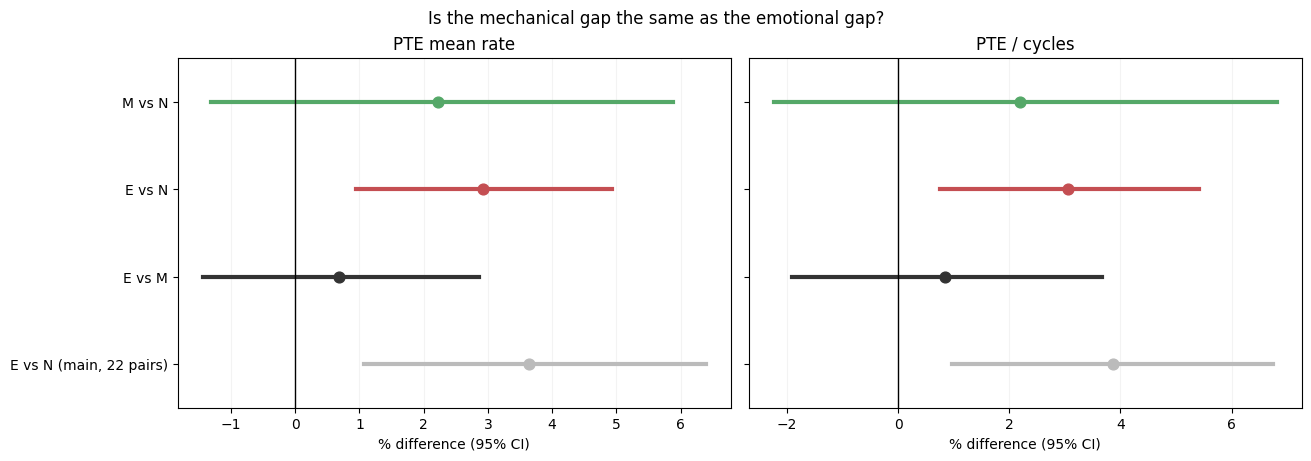

In [5]:
fig, axes = plt.subplots(1, len(SPECS), figsize=(13, 4.5), sharey=True, layout="constrained")
rows = ["M vs N", "E vs N", "E vs M", "E vs N (main, 22 pairs)"]
colors = [COLORS["mechanical"], COLORS["emotional"], "#333333", "#BBBBBB"]
for ax, feature in zip(axes, FEATURES):
    sub = summary.loc[summary.feature == feature].set_index("comparison")
    ref = reference.loc[feature]
    points = [(sub.loc[r, "estimate"], sub.loc[r, "ci_low"], sub.loc[r, "ci_high"]) for r in rows[:3]]
    points.append((ref.display_estimate, ref.display_ci_low, ref.display_ci_high))
    for i, ((estimate, low, high), color) in enumerate(zip(points, colors)):
        ax.plot([low, high], [i, i], color=color, linewidth=3)
        ax.scatter(estimate, i, color=color, s=60, zorder=3)
    ax.axvline(0, color="black", linewidth=1)
    ax.set(title=LABELS[feature], xlabel="% difference (95% CI)", yticks=range(len(rows)),
           yticklabels=rows, ylim=(len(rows) - .5, -.5))
    ax.grid(axis="x", alpha=.15)
fig.suptitle("Is the mechanical gap the same as the emotional gap?")
save_figure(fig, "overall_effects")

## 4. Conclusion

- **M vs N** answers "does mechanical differ from neutral at all?"
- **E vs M** answers the main question, "is the emotional gap different from the mechanical gap?"

**Limits:**
- Only **5 nodes on 1 date**, so the tests have little power and the CIs are wide.
- **Run timing:** on this date, N and M runs were interleaved in the morning, but all E runs ran together in a separate session in the afternoon (see the run-order table in section 1). M vs N is therefore the cleanest comparison here. E vs N and E vs M are also comparisons between two sessions of the day.
- This is one date, so we can't check whether the result holds across days.

In [6]:
for feature in FEATURES:
    sub = summary.loc[summary.feature == feature].set_index("comparison")
    mn, em = sub.loc["M vs N"], sub.loc["E vs M"]
    ref = reference.loc[feature]
    covers = mn.ci_low <= ref.display_estimate <= mn.ci_high
    display(Markdown(
        f"**{LABELS[feature]}:** mechanical vs neutral = **{mn.estimate:+.2f}%** "
        f"(95% CI {mn.ci_low:+.2f} to {mn.ci_high:+.2f}; Bonferroni p = {mn.p_t_bonferroni:.3g}; "
        f"M higher in {mn.n_positive}/{mn.n_nodes} nodes). "
        f"Emotional vs mechanical = **{em.estimate:+.2f}%** "
        f"(95% CI {em.ci_low:+.2f} to {em.ci_high:+.2f}; Bonferroni p = {em.p_t_bonferroni:.3g}). "
        f"The main E−N estimate ({ref.display_estimate:+.2f}%) is "
        f"**{'inside' if covers else 'outside'}** the M−N range."))

for source in sources.itertuples(index=False):
    assert hashlib.sha256((ROOT / source.path).read_bytes()).hexdigest() == source.sha256
print("Verified: input metadata and feature files are unchanged.")
print(f"Tables and figures: {OUT.relative_to(ROOT)}")

**PTE mean rate:** mechanical vs neutral = **+2.22%** (95% CI -1.31 to +5.87; Bonferroni p = 0.316; M higher in 4/5 nodes). Emotional vs mechanical = **+0.69%** (95% CI -1.44 to +2.86; Bonferroni p = 0.846). The main E−N estimate (+3.64%) is **inside** the M−N range.

**PTE / cycles:** mechanical vs neutral = **+2.19%** (95% CI -2.24 to +6.81; Bonferroni p = 0.493; M higher in 4/5 nodes). Emotional vs mechanical = **+0.85%** (95% CI -1.90 to +3.68; Bonferroni p = 0.889). The main E−N estimate (+3.86%) is **inside** the M−N range.

Verified: input metadata and feature files are unchanged.
Tables and figures: results/fulltrace_matched_MN_2026-10-24_two_features
